# The J++ lens, rebuilt in TorchLens

<a href="https://colab.research.google.com/github/johnmarktaylor91/torchlens/blob/wip/jfilter-lens/notebooks/jfilter_lens.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Jacobian lens (J-lens) of [Gurnee et al. (2026)](https://transformer-circuits.pub/2026/workspace/index.html) reads an intermediate activation as the tokens the model is disposed to say: it maps the activation into the final layer with one averaged Jacobian per layer, then applies the unembedding. The **J++ lens** of Kola Ayonrinde and Jack Lindsey ([LessWrong, October 2026](https://www.lesswrong.com/posts/nc9dHfcB22JdMzGbr/j-lens-jacobian-filtering-enables-more-faithful-workspace); [code](https://github.com/safety-research/jpp_lens)) keeps that single matrix but estimates it better: it clusters the source activations, fits one "expert" Jacobian per cluster and learns weights that down-weight the experts whose readouts are poor (**Jacobian Filtering**), computes every Jacobian with Layer-wise Relevance Propagation stop-gradients (**LRP**, as in the R-lens), and ranks only tokens that contain a letter or digit (**Readout Filtering**).

This notebook rebuilds the method with [TorchLens](https://github.com/johnmarktaylor91/torchlens) on a small model and reruns the post's headline comparison (logit lens, J-lens, R-lens, J++ lens; recall@10 of intermediate variables on the post's five readout tasks). The LRP rules are three TorchLens interventions; the expert Jacobians come from the same backward passes as the plain J-lens.

In [1]:
# !pip -q install torchlens datasets   # Colab already has torch, transformers, scikit-learn and matplotlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torchlens") is None or importlib.util.find_spec("datasets") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install", "torchlens", "datasets"], check=True
    )

## Setup

Model choice: **Qwen2.5-0.5B**. It is the smallest model in the family the post evaluates on, and it has the same block structure as the post's Qwen models (RMSNorm, a SiLU-gated MLP), so all three LRP rules apply exactly as the post specifies. It also answers more of the readout tasks' prompts correctly than GPT-2 small or SmolLM2, which matters because the post scores multihop, multilingual and poetry items only when the model gets the final answer right.

Settings follow the post (its Table 5) except one: WikiText-103 sequences of 128 tokens with the first 16 positions and the last dropped, 8 experts per layer, seven equally spaced readout layers, but **16** fitting sequences instead of the post's 64, so that a free Colab GPU finishes in about 15 minutes (the Jacobians cost one backward pass per 32 output dimensions per batch of sequences). The fit-size check at the end shows what that costs, and the last section reports the same run at the post's full 64 sequences. On CPU the notebook fits on a single sequence so that it finishes; those numbers only show that the code runs.

In [2]:
import json
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from datasets import load_dataset
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from transformers import AutoModelForCausalLM, AutoTokenizer

import torchlens as tl

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = DEVICE == "cuda"
MODEL = "Qwen/Qwen2.5-0.5B"
N_FIT = 16 if GPU else 1  # sequences for the Jacobians (post: 64; see the setup note)
N_CLUSTER = 512 if GPU else 32  # sequences for the k-means routers (post: 1,000)
SEQ_LEN, SKIP = 128, 16  # 128 tokens; drop the first 16 positions and the last
E = 8  # experts per layer (post: 8)
BATCH = 4 if GPU else 1  # sequences per traced forward
CHUNK = 32  # Jacobian rows per batched backward pass (a memory knob: 64 needs more than 11 GB)
SEED = 0
torch.manual_seed(SEED)
t_start = time.time()

tok = AutoTokenizer.from_pretrained(MODEL)
model = (
    AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32, attn_implementation="eager")
    .to(DEVICE)
    .eval()
)
L, D = model.config.num_hidden_layers, model.config.hidden_size
BLOCKS = [f"model.layers.{i}" for i in range(L)]
LAYERS = [L * k // 8 for k in range(1, 8)]  # 3, 6, ..., 21: residual stream after that many blocks
SOURCES = [BLOCKS[layer - 1] for layer in LAYERS]


def unembed(x):
    """The model's own readout: final RMSNorm, then the LM head."""
    return model.lm_head(model.model.norm(x))


print(f"{MODEL}: {L} blocks, d_model {D}, readout layers {LAYERS}, device {DEVICE}")

Qwen/Qwen2.5-0.5B: 24 blocks, d_model 896, readout layers [3, 6, 9, 12, 15, 18, 21], device cuda


## The LRP rules are three TorchLens interventions

The R-lens and J++ lens compute each Jacobian through an LRP backward pass. The post's rules (its Table 5) leave every forward value unchanged and only change gradients: the **LN-rule** freezes the RMSNorm scale `rsqrt(mean(x^2) + eps)`, the **identity rule** treats `silu(z) = z * sigmoid(z)` as linear in `z` by freezing the sigmoid, and the **half rule** sends half the gradient through each side of the gated MLP's product. Attention keeps its plain gradient. In TorchLens each rule is one `tl.when(selector, edit)`: the selector picks the ops by the function they call, and the edit returns the same value with a different autograd graph.

In [3]:
in_mlp = tl.in_module(f"{BLOCKS[0]}.mlp")
for block in BLOCKS[1:]:
    in_mlp = in_mlp | tl.in_module(f"{block}.mlp")


def ln_rule(out, *, ctx):
    """RMSNorm: hold the scale rsqrt(mean(x^2) + eps) constant."""
    return out.detach()


def identity_rule(out, *, ctx):
    """SiLU: silu(z) = z * sigmoid(z), with the sigmoid held constant."""
    z = ctx.args[0]
    return z * torch.sigmoid(z).detach()


def half_rule(out, *, ctx):
    """Gated-MLP product: send half of the gradient through it."""
    return 0.5 * out + 0.5 * out.detach()


LRP = (
    tl.when(tl.func("rsqrt"), ln_rule)
    & tl.when(tl.func("silu"), identity_rule)
    & tl.when(tl.func("mul") & in_mlp, half_rule)
)


def residual_stream(ids, rules=None):
    """One traced forward. Returns the live residual stream after each readout layer and after the last block."""
    # save_mode="view" keeps the live tensors themselves, so the model's output can be differentiated with
    # respect to them; they are aliases rather than copies, so the copy-sized save budget is switched off.
    capture = tl.options.CaptureOptions(save_mode="view", save_budget=None)
    trace = tl.trace(model, ids, capture=capture, intervene=rules)
    return [trace[block].out for block in SOURCES], trace[BLOCKS[-1]].out


# The rules change gradients, never values: the LRP forward matches the plain one.
probe = tok("The rules change gradients, never values.", return_tensors="pt").input_ids.to(DEVICE)
with torch.no_grad():
    plain, lrp = residual_stream(probe)[1], residual_stream(probe, LRP)[1]
print(
    f"largest LRP-vs-plain forward difference: {float((plain - lrp).abs().max() / plain.abs().max()):.1e} of the largest activation"
)

largest LRP-vs-plain forward difference: 6.9e-07 of the largest activation


## Fitting text and the k-means routers

The post clusters the residual stream at each readout layer into 8 regions: unit-normalise each activation, project onto the top 64 principal components, then k-means. `tl.extract` returns the residual stream at the seven readout layers and scikit-learn does the clustering.

In [4]:
def wikitext_sequences(n, seed):
    """n sequences of SEQ_LEN tokens, each from a different WikiText-103 paragraph with at least SEQ_LEN tokens."""
    stream = load_dataset(
        "Salesforce/wikitext", "wikitext-103-raw-v1", split="train", streaming=True
    )
    seqs = []
    for row in stream.shuffle(seed=seed, buffer_size=20_000):
        ids = tok(row["text"]).input_ids
        if len(ids) >= SEQ_LEN:
            seqs.append(ids[:SEQ_LEN])
            if len(seqs) == n:
                return torch.tensor(seqs)


fit_seqs = wikitext_sequences(N_FIT, seed=SEED)
cluster_seqs = wikitext_sequences(N_CLUSTER, seed=SEED + 1)
KEEP = slice(SKIP, SEQ_LEN - 1)

acts = [[] for _ in SOURCES]
with torch.no_grad():
    for ids in cluster_seqs.split(32):
        outs = tl.extract(model, ids.to(DEVICE), {block: block for block in SOURCES})
        for store, block in zip(acts, SOURCES):
            store.append(outs[block][:, KEEP].reshape(-1, D).float().cpu())
routers = [
    make_pipeline(
        Normalizer(), PCA(64, random_state=SEED), KMeans(E, n_init=1, random_state=SEED)
    ).fit(torch.cat(a).numpy())
    for a in acts
]
del acts
print(f"routers fitted on {N_CLUSTER * (SEQ_LEN - SKIP - 1):,} positions per layer")

routers fitted on 56,832 positions per layer


## Expert Jacobians (Eq. 2a of the post)

One backward pass per chunk of output rows gives the gradient of the final residual (summed over every kept target position) with respect to the residual stream at every source position and every readout layer at once. The plain J-lens averages those per-position gradients over all positions. J++ instead sums them per k-means cluster: the same gradients, scattered into `E` accumulators. The plain average is recovered exactly as the cluster-share-weighted sum of the experts, `J = sum_i (n_i / N) J_i`, so one fit gives both the pooled lens and its experts. We run it twice: once with the plain backward pass (J-lens) and once under the LRP rules (R-lens and J++).

In [5]:
def fit_experts(seqs, rules=None):
    """Per-cluster sums of d h_final / d h_layer and per-cluster position counts, for every readout layer."""
    sums = torch.zeros(len(SOURCES), E, D, D, device=DEVICE)
    counts = torch.zeros(len(SOURCES), E, device=DEVICE)
    for ids in seqs.split(BATCH):
        sources, final = residual_stream(ids.to(DEVICE), rules)
        clusters = [
            F.one_hot(
                torch.as_tensor(
                    r.predict(h[:, KEEP].reshape(-1, D).detach().cpu().numpy()), dtype=torch.long
                ),
                E,
            )
            .float()
            .to(DEVICE)
            for r, h in zip(routers, sources)
        ]
        target = final[:, KEEP].sum((0, 1))  # a cotangent at every kept target position
        for start in range(0, D, CHUNK):
            rows = torch.eye(D, device=DEVICE)[start : start + CHUNK]
            grads = torch.autograd.grad(
                target, sources, grad_outputs=rows, is_grads_batched=True, retain_graph=True
            )
            for i, (grad, onehot) in enumerate(zip(grads, clusters)):
                per_position = grad[:, :, KEEP].reshape(len(rows), -1, D)
                sums[i, :, start : start + CHUNK] += torch.einsum(
                    "rpd,pe->erd", per_position, onehot
                )
        counts += torch.stack([c.sum(0) for c in clusters])
        del sources, final, target, grads, clusters, per_position  # free this trace before the next
        if GPU:
            torch.cuda.empty_cache()
    return sums, counts


# Each half of the fitting text is fitted separately so that the fit-size check at the end costs nothing extra.
fits = {}
for name, rules in (("plain", None), ("lrp", LRP)):
    t0 = time.time()
    fits[name] = [fit_experts(part, rules) for part in fit_seqs.chunk(2)]
    print(f"{name} fit: {time.time() - t0:.0f}s")
full_fit = {
    name: (sum(s for s, _ in parts), sum(c for _, c in parts)) for name, parts in fits.items()
}


def expert_jacobians(sums, counts, min_positions=50):
    """J_i = mean over cluster i's positions; like the released code, an expert with fewer than 50 positions falls back to the pooled J."""
    pooled = sums.sum(1) / counts.sum(1)[:, None, None]
    experts = sums / counts[..., None, None].clamp(min=1)
    return torch.where((counts < min_positions)[..., None, None], pooled[:, None], experts)


shares = full_fit["lrp"][1] / full_fit["lrp"][1].sum(1, keepdim=True)
print("fit positions per expert at layer", LAYERS[0], ":", full_fit["lrp"][1][0].int().tolist())

plain fit: 196s


lrp fit: 206s
fit positions per expert at layer 3 : [184, 254, 32, 189, 98, 275, 712, 32]


## The readout evals

The post's five latent-variable tasks (data from `anthropics/jacobian-lens` via the J++ repository, Apache-2.0): multihop, multilingual, typo, association and poetry. Each item has a prompt, a readout position (the last prompt token; for poetry the end of the first line) and one or more intermediate variables. An intermediate counts as read out at a layer if any of its single-token surface forms (with or without a leading space; as written, capitalised or lowercase) is in the top 10 tokens. As in the post: multihop, multilingual and poetry items are kept only when the model answers them correctly; 20% of the items of each task form the dev set that fits the J++ weights, and every lens is scored on the other 80%.

In [6]:
EVALS = (
    "https://raw.githubusercontent.com/safety-research/jpp_lens/d7efc0de372e/data/jlens/evaluations"
)
TASKS = ["multihop", "multilingual", "typo", "association", "poetry"]


def candidates(word):
    forms = {p + w for w in {word, word.capitalize(), word.lower()} for p in ("", " ")}
    return sorted(
        {
            ids[0]
            for ids in (tok(f, add_special_tokens=False).input_ids for f in forms)
            if len(ids) == 1
        }
    )


def answers_correctly(task, item, next_token):
    """The post's correctness rule: the greedy next token is the target or a leading piece of it."""
    target = (
        item.get("target")
        if task in ("multihop", "multilingual")
        else item["intermediates"][0]
        if task == "poetry"
        else None
    )
    word = tok.decode(next_token).lstrip()
    return target is None or (bool(word) and target.strip().startswith(word))


raw = [
    (task, item)
    for task in TASKS
    for item in json.load(urllib.request.urlopen(f"{EVALS}/lens-eval-{task}.json"))["items"]
]
raw = [
    (task, item, cands)
    for task, item in raw
    if (cands := [c for c in map(candidates, item["intermediates"]) if c])
]
# Right padding with causal attention: a real token never attends to the pads after it, so no mask is needed.
tok.padding_side = "right"
items = []
for start in range(0, len(raw), 32):
    group = raw[start : start + 32]
    enc = tok([item["prompt"] for _, item, _ in group], return_tensors="pt", padding=True).to(
        DEVICE
    )
    with torch.no_grad():
        outs = tl.extract(model, enc.input_ids, {block: block for block in SOURCES})
        resid = torch.stack([outs[block] for block in SOURCES], 1)  # [prompts, layers, tokens, d]
        logits = model(enc.input_ids).logits
    for b, (task, item, cands) in enumerate(group):
        n = int(enc.attention_mask[b].sum())
        pos = (
            n - 1
            if task != "poetry"
            else max(i for i in range(n) if "\n" in tok.decode(enc.input_ids[b, i]))
        )
        correct = answers_correctly(task, item, logits[b, n - 1].argmax())
        items.append(
            {
                "task": task,
                "name": item["name"],
                "cands": cands,
                "h": resid[b, :, pos],
                "correct": correct,
                "dev": False,
            }
        )

rng = np.random.default_rng(SEED)
for task in TASKS:
    members = [it for it in items if it["task"] == task and it["correct"]]
    for j, k in enumerate(rng.permutation(len(members))):
        members[k]["dev"] = j < max(1, int(0.2 * len(members)))
dev = [it for it in items if it["dev"]]
test = [it for it in items if it["correct"] and not it["dev"]]
test_all = [it for it in items if not it["dev"]]  # secondary: no correctness filter
print(
    "scored (held-out) items:",
    {t: sum(it["task"] == t for it in test) for t in TASKS},
    "| dev items:",
    len(dev),
)
print(
    "answered correctly:",
    {
        t: f"{sum(it['correct'] for it in items if it['task'] == t)}/{sum(it['task'] == t for it in items)}"
        for t in TASKS
    },
)

# Readout Filtering: tokens with no letter or digit (the post's V_sem), sparing every scored surface form.
vocab = model.lm_head.out_features
nonsemantic = torch.tensor(
    [not any(ch.isalnum() for ch in tok.decode([i])) for i in range(vocab)], device=DEVICE
)
nonsemantic[[c for it in items for cs in it["cands"] for c in cs]] = False
print(f"Readout Filtering removes {int(nonsemantic.sum()):,} of {vocab:,} tokens")

scored (held-out) items: {'multihop': 11, 'multilingual': 10, 'typo': 77, 'association': 80, 'poetry': 0} | dev items: 42
answered correctly: {'multihop': '13/84', 'multilingual': '12/107', 'typo': '96/96', 'association': '99/99', 'poetry': '0/98'}


Readout Filtering removes 10,314 of 151,936 tokens


## Scoring

`hits` returns, for every item, layer and intermediate, whether the intermediate is in the lens's top 10 at that layer. An item's score is the fraction of its intermediates read out at any of the seven layers; the task score is the mean over its items; the headline is the macro mean over the five tasks (the post's recall@10).

In [7]:
def hits(lens, group, k=10, filtered=True, layers=None):
    """[items][layers, intermediates] booleans: is the intermediate in the lens's top k at that layer?"""
    layers = range(len(LAYERS)) if layers is None else layers
    out = []
    for it in group:
        with torch.no_grad():
            logits = torch.stack([lens(i, it["h"][i]) for i in layers])
        if filtered:
            logits = logits.masked_fill(nonsemantic, float("-inf"))
        best = torch.stack(
            [logits[:, c].max(1).values for c in it["cands"]], 1
        )  # [layers, intermediates]
        out.append(((logits[:, None, :] > best[:, :, None]).sum(-1) < k).cpu())
    return out


def recall(h, group, layer=None):
    """Macro recall@10: per item the fraction of intermediates hit (at any layer, or at one layer)."""
    per_item = np.array(
        [(x.any(0) if layer is None else x[layer]).float().mean().item() for x in h]
    )
    tasks = np.array([it["task"] for it in group])
    return float(np.mean([per_item[tasks == t].mean() for t in TASKS if (tasks == t).any()]))


def jacobian_lens(J):
    """A lens from one d_model x d_model matrix per layer: unembed(J_l h)."""
    return lambda i, h: unembed(h @ J[i].T)


def logit_lens(i, h):
    """The logit lens: the transport map is the identity."""
    return unembed(h)

## Jacobian Filtering: learning the expert weights

Per layer, the post learns one signed weight per expert on the dev items, maximising that layer's recall@10. Recall is piecewise constant in the weights, so the optimiser climbs a smooth stand-in: a sigmoid of the margin between the best candidate's logit and the 10th-largest logit, in units of the logit spread (temperature 0.1), with Adam at learning rate 0.05 for 200 steps from three starts (uniform, the best single expert, the mean of the top three), keeping the weights with the best exact dev recall. The helper follows the released code (`condense_experts/`). Because the final norm is an RMSNorm, the logits of `sum_i w_i J_i h` are a positive rescaling of `sum_i w_i W_U diag(g) J_i h`, so the per-expert logits are computed once per layer and the objective is linear in the weights.

In [8]:
def fit_weights(experts_l, layer, group, steps=200, lr=0.05, temperature=0.1, k=10):
    """Signed unit-norm weights over one layer's expert Jacobians, fitted on the dev items' recall@k."""
    H = torch.stack([it["h"][layer] for it in group])  # [P, d]
    with torch.no_grad():
        cache = model.lm_head(
            model.model.norm.weight * torch.einsum("edk,pk->ped", experts_l, H)
        )  # [P, E, vocab]
    pairs = [(p, c) for p, it in enumerate(group) for c in it["cands"]]
    task_of = torch.tensor([TASKS.index(group[p]["task"]) for p, _ in pairs], device=DEVICE)
    pad = max(len(c) for _, c in pairs)
    cand = torch.tensor([c + c[:1] * (pad - len(c)) for _, c in pairs], device=DEVICE)
    rows = torch.tensor([p for p, _ in pairs], device=DEVICE)

    def macro(values):
        per_task = [values[task_of == t].mean() for t in range(len(TASKS)) if (task_of == t).any()]
        return torch.stack(per_task).mean()

    def margins(w):
        logits = torch.einsum("pev,e->pv", cache, w / w.norm())[rows]
        spread = logits.std(1).detach()
        logits = logits.masked_fill(nonsemantic, float("-inf"))  # Readout Filtering
        return logits.gather(1, cand).max(1).values - logits.topk(k, 1).values[:, -1], spread

    single = torch.tensor(
        [
            macro(
                (margins(F.one_hot(torch.tensor(e), E).float().to(DEVICE))[0] >= 0).float()
            ).item()
            for e in range(E)
        ]
    )
    starts = [
        torch.ones(E),
        F.one_hot(single.argmax(), E).float(),
        torch.zeros(E).index_fill(0, single.topk(3).indices, 1.0),
    ]
    best_w, best_score = starts[0].to(DEVICE), -1.0
    for w0 in starts:
        w = w0.to(DEVICE).clone().requires_grad_(True)
        opt = torch.optim.Adam([w], lr=lr)
        for step in range(steps + 1):
            margin, spread = margins(w)
            if step % 5 == 0:
                score = macro((margin >= 0).float()).item()
                if score > best_score:
                    best_w, best_score = (w / w.norm()).detach().clone(), score
            loss = -macro(torch.sigmoid(margin / (temperature * spread)))
            opt.zero_grad()
            loss.backward()
            opt.step()
    return best_w, single


def build_lenses(fit):
    """Every lens from one fit ({"plain" | "lrp": (per-cluster sums, counts)}): the J-, R- and J++ lenses and the no-LRP ablation."""
    experts = {name: expert_jacobians(*sc) for name, sc in fit.items()}
    pooled = {
        name: sums.sum(1) / counts.sum(1)[:, None, None] for name, (sums, counts) in fit.items()
    }
    weights = {
        name: torch.stack([fit_weights(ex[i], i, dev)[0] for i in range(len(LAYERS))])
        for name, ex in experts.items()
    }

    def mix(name):
        return jacobian_lens(torch.einsum("le,ledk->ldk", weights[name], experts[name]))

    lenses = {
        "Logit lens": logit_lens,
        "J-lens": jacobian_lens(pooled["plain"]),  # all positions averaged, plain gradient
        "R-lens": jacobian_lens(pooled["lrp"]),  # all positions averaged, LRP gradient
        "J++ lens": mix("lrp"),  # learned expert weights, LRP gradient
        "Jacobian Filtering without LRP": mix("plain"),
    }
    return lenses, experts, weights


t0 = time.time()
all_lenses, experts, weights = build_lenses(full_fit)
print(f"weights fitted in {time.time() - t0:.0f}s")
print("J++ weights at the first readout layer:", [round(x, 2) for x in weights["lrp"][0].tolist()])

weights fitted in 50s
J++ weights at the first readout layer: [0.03, -0.6, 0.49, 0.01, 0.58, -0.07, 0.22, -0.09]


## The comparison

In [9]:
lenses = {name: all_lenses[name] for name in ("Logit lens", "J-lens", "R-lens", "J++ lens")}
H = {name: hits(lens, test) for name, lens in lenses.items()}
H["J++ without Readout Filtering"] = hits(lenses["J++ lens"], test, filtered=False)
H["Jacobian Filtering without LRP"] = hits(all_lenses["Jacobian Filtering without LRP"], test)
H["J-lens, unfiltered readout"] = hits(lenses["J-lens"], test, filtered=False)


def bootstrap(h, group, n=1000):
    """95% interval of the macro recall, resampling items within each task."""
    tasks = np.array([it["task"] for it in group])
    per_item = np.array([x.any(0).float().mean().item() for x in h])
    draws = np.random.default_rng(SEED)
    present = [t for t in TASKS if (tasks == t).any()]
    stats = [
        np.mean([draws.choice(per_item[tasks == t], (tasks == t).sum()).mean() for t in present])
        for _ in range(n)
    ]
    return np.percentile(stats, [2.5, 97.5])


def per_task(h, group):
    per_item = np.array([x.any(0).float().mean().item() for x in h])
    tasks = np.array([it["task"] for it in group])
    return [per_item[tasks == t].mean() if (tasks == t).any() else float("nan") for t in TASKS]


def table(H, group):
    print(f"{'lens':34s} {'macro':>6s}   95% CI         " + " ".join(f"{t[:8]:>8s}" for t in TASKS))
    for name, h in H.items():
        lo, hi = bootstrap(h, group)
        print(
            f"{name:34s} {100 * recall(h, group):6.1f}   [{100 * lo:4.1f}, {100 * hi:4.1f}]   "
            + " ".join(f"{100 * v:8.1f}" for v in per_task(h, group))
        )


print(
    "Recall@10 (%) on held-out items the model answers correctly (the post's protocol); nan = no such items"
)
table(H, test)
print("\nSecondary check, every held-out item whether or not the model answers it correctly:")
table({name: hits(lens, test_all) for name, lens in lenses.items()}, test_all)
print(f"\ntotal wall time so far: {(time.time() - t_start) / 60:.1f} min")

Recall@10 (%) on held-out items the model answers correctly (the post's protocol); nan = no such items
lens                                macro   95% CI         multihop multilin     typo associat   poetry
Logit lens                           10.9   [ 4.2, 18.5]       27.3     10.0      6.5      0.0      nan
J-lens                               33.4   [25.7, 41.9]       45.5     32.5     55.8      0.0      nan


R-lens                               31.2   [23.5, 40.0]       36.4     27.5     61.0      0.0      nan
J++ lens                             35.4   [27.1, 44.2]       45.5     27.5     68.8      0.0      nan
J++ without Readout Filtering        34.8   [26.5, 43.4]       45.5     25.0     68.8      0.0      nan


Jacobian Filtering without LRP       40.2   [32.8, 48.3]       45.5     40.0     75.3      0.0      nan
J-lens, unfiltered readout           28.6   [20.5, 37.0]       45.5     32.5     36.4      0.0      nan

Secondary check, every held-out item whether or not the model answers it correctly:


lens                                macro   95% CI         multihop multilin     typo associat   poetry
Logit lens                            5.3   [ 3.4,  7.4]       15.9      4.0      6.5      0.0      0.0


J-lens                               23.3   [20.2, 26.5]       30.5     29.1     55.8      0.0      1.0
R-lens                               23.5   [20.4, 26.5]       36.6     19.8     61.0      0.0      0.0


J++ lens                             21.5   [18.3, 24.3]       27.4     11.2     68.8      0.0      0.0

total wall time so far: 8.8 min


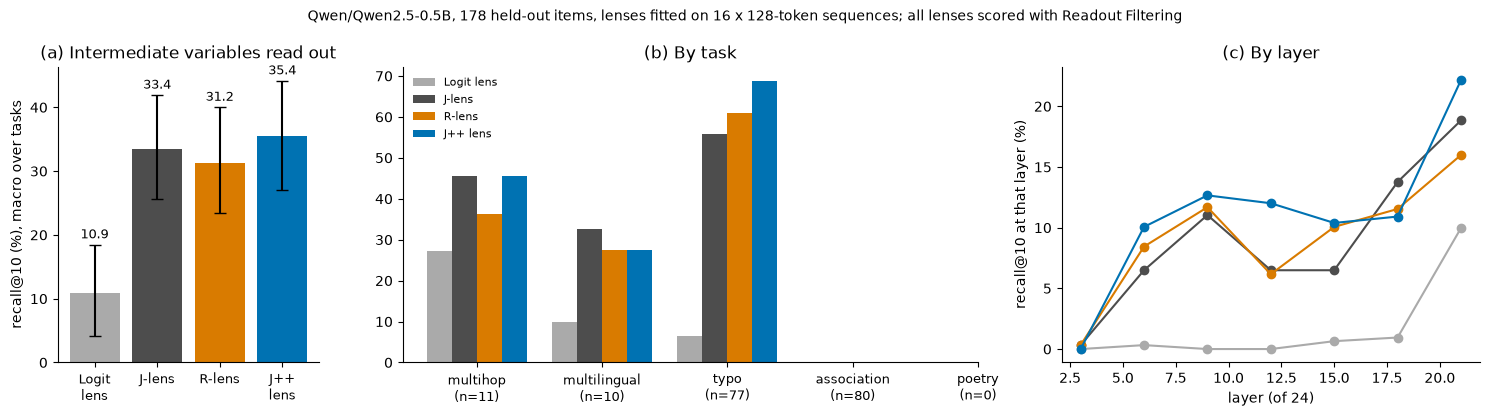

In [10]:
colors = {"Logit lens": "#AAAAAA", "J-lens": "#4D4D4D", "R-lens": "#D97B00", "J++ lens": "#0072B2"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2.2, 1.6]})
ax = axes[0]
for x, name in enumerate(lenses):
    lo, hi = bootstrap(H[name], test)
    r = recall(H[name], test)
    ax.bar(x, 100 * r, color=colors[name], yerr=[[100 * (r - lo)], [100 * (hi - r)]], capsize=4)
    ax.text(x, 100 * hi + 1, f"{100 * r:.1f}", ha="center", fontsize=9)
ax.set_xticks(range(len(lenses)), [n.replace(" lens", "\nlens") for n in lenses], fontsize=9)
ax.set_ylabel("recall@10 (%), macro over tasks")
ax.set_title("(a) Intermediate variables read out")
ax = axes[1]
width = 0.2
for j, name in enumerate(lenses):
    ax.bar(
        np.arange(len(TASKS)) + (j - 1.5) * width,
        100 * np.array(per_task(H[name], test)),
        width,
        color=colors[name],
        label=name,
    )
counts = [sum(it["task"] == t for it in test) for t in TASKS]
ax.set_xticks(range(len(TASKS)), [f"{t}\n(n={c})" for t, c in zip(TASKS, counts)], fontsize=9)
ax.set_title("(b) By task")
ax.legend(fontsize=8, frameon=False)
ax = axes[2]
for name in lenses:
    ax.plot(
        LAYERS,
        [100 * recall(H[name], test, layer=i) for i in range(len(LAYERS))],
        "o-",
        color=colors[name],
        label=name,
    )
ax.set_xlabel(f"layer (of {L})")
ax.set_ylabel("recall@10 at that layer (%)")
ax.set_title("(c) By layer")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.suptitle(
    f"{MODEL}, {len(test)} held-out items, lenses fitted on {N_FIT} x {SEQ_LEN}-token sequences; all lenses scored with Readout Filtering",
    fontsize=10,
)
plt.tight_layout()
plt.show()

## Why filtering helps: the experts are uneven

The post's Figure 3 applies each expert Jacobian alone, at its own layer, to every eval item. Some experts read out intermediates well even outside their own cluster; others are close to useless, and the pooled Jacobian (the cluster-share-weighted average) mixes them all in. The learned weights mostly decide which experts to drop.

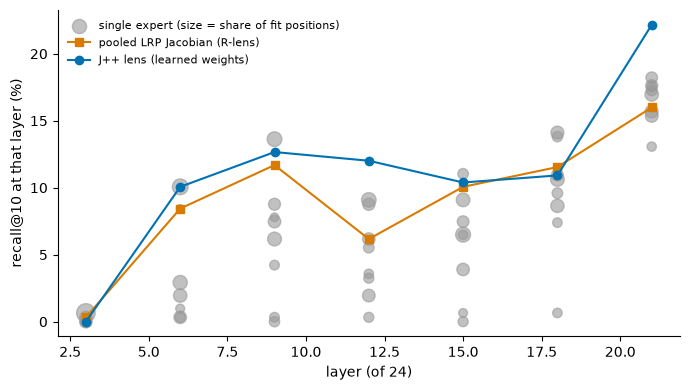

learned weights (rows: layers, columns: experts):
[[ 0.03 -0.6   0.49  0.01  0.58 -0.07  0.22 -0.09]
 [ 0.27  0.14 -0.07  0.91  0.07 -0.25  0.09 -0.07]
 [ 0.31  0.29  0.31  0.09  0.54  0.44  0.48  0.04]
 [ 0.34  0.04  0.52  0.24  0.71  0.   -0.15  0.19]
 [-0.15  0.69 -0.01  0.42  0.11  0.24  0.5   0.01]
 [-0.16  0.5   0.14 -0.09 -0.13  0.18  0.4   0.69]
 [ 0.34  0.52 -0.21  0.41 -0.22 -0.59  0.02 -0.02]]


In [11]:
expert_recall = np.zeros((len(LAYERS), E))
for i in range(len(LAYERS)):
    for e in range(E):
        one_expert = jacobian_lens({i: experts["lrp"][i, e]})
        expert_recall[i, e] = recall(hits(one_expert, test, layers=[i]), test, layer=0)
fig, ax = plt.subplots(figsize=(7, 4))
for i, layer in enumerate(LAYERS):
    ax.scatter(
        [layer] * E,
        100 * expert_recall[i],
        s=20 + 400 * shares[i].cpu().numpy(),
        color="#999999",
        alpha=0.6,
        label="single expert (size = share of fit positions)" if i == 0 else None,
    )
ax.plot(
    LAYERS,
    [100 * recall(H["R-lens"], test, layer=i) for i in range(len(LAYERS))],
    "s-",
    color=colors["R-lens"],
    label="pooled LRP Jacobian (R-lens)",
)
ax.plot(
    LAYERS,
    [100 * recall(H["J++ lens"], test, layer=i) for i in range(len(LAYERS))],
    "o-",
    color=colors["J++ lens"],
    label="J++ lens (learned weights)",
)
ax.set_xlabel(f"layer (of {L})")
ax.set_ylabel("recall@10 at that layer (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
print("learned weights (rows: layers, columns: experts):")
print(np.round(weights["lrp"].cpu().numpy(), 2))

## Fit size: is 16 sequences enough?

The two halves of the fitting text were fitted separately, so the lenses can be rebuilt from the first half alone (8 sequences on the default GPU setting) at no extra cost. If the scores still move between half and full, the lenses are under-fit at this size.

In [12]:
if len(fits["lrp"]) == 2:
    half_lenses, _, _ = build_lenses({name: parts[0] for name, parts in fits.items()})
    print(f"{'lens':12s} {'half fit':>9s} {'full fit':>9s}   (macro recall@10 %, held-out items)")
    for name in lenses:
        print(
            f"{name:12s} {100 * recall(hits(half_lenses[name], test), test):9.1f} {100 * recall(H[name], test):9.1f}"
        )
print(f"total wall time: {(time.time() - t_start) / 60:.1f} min")

lens          half fit  full fit   (macro recall@10 %, held-out items)


Logit lens        10.9      10.9


J-lens            34.4      33.4


R-lens            32.5      31.2


J++ lens          34.1      35.4
total wall time: 10.0 min


## What this shows

On Qwen2.5-0.5B the J++ lens comes out on top of the post's four headline lenses, but by a small margin that is within the noise of this evaluation; the post's large gain does not reproduce clearly at this scale.

Macro recall@10 (%) on held-out items the model answers correctly. The first column is this notebook's run (16 fitting sequences, on an RTX 2080 Ti); the second is the same code with `N_FIT = 64`, the post's fit size (about 28 minutes of fitting on the same GPU); the third is the post's Qwen3.6-27B (its Figure 1, Tables 1, 2 and 3b).

| Lens | 16 sequences | 64 sequences | Post, Qwen3.6-27B |
|---|---:|---:|---:|
| Logit lens | 10.9 | 10.9 | 31.1 |
| J-lens | 33.4 | 31.8 | 35.7 |
| R-lens | 31.2 | 31.5 | 37.7 |
| **J++ lens** | **35.4** | **35.1** | **55.2** |
| J++ without Readout Filtering | 34.8 | 33.9 | 52.3 |
| Jacobian Filtering without LRP | 40.2 | 38.0 | 48.6 |

What matches the post:

- The Jacobian lenses read out far more intermediate variables than the logit lens (about three times as many here; the 27B model's logit lens is much stronger, so the post's gap is smaller).
- J++ is the best of the four headline lenses, and the gain is clearest on the typo task (64 sequences: J-lens 49.4, R-lens 59.7, J++ 67.5; the post: 60.4, 66.7, 91.7).
- Readout Filtering helps a little, as in the post (J++ 33.9 without it, 35.1 with it at 64 sequences; the post: 52.3 and 55.2).
- The experts are uneven (the scatter above): at most layers single experts range from near zero to about the pooled Jacobian or above it, and the learned weights are signed and far from the cluster shares.

What does not match, and why the numbers are weak evidence either way:

- The margin is small: J++ is 3.6 points above the R-lens at the post's fit size, against 17.5 in the post, and the 95% intervals overlap by a wide margin. Only 178 held-out items are scored (11 multihop, 10 multilingual, 77 typo, 80 association), because this small model answers few multihop and multilingual prompts and no poetry prompt correctly.
- Every lens scores 0 on association (the post's 27B model: 9 to 37%), so a quarter of the macro average carries no signal, and poetry has no scorable items at all.
- Dropping the LRP rules scores higher here (38.0 against 35.1), the opposite of the post's ablation (6.6 points lower without LRP). With these intervals the difference is also within noise.
- Fit size: the plain and LRP Jacobians barely change between 16 and 64 sequences, so they are not under-fit. The J++ score at 16 and 64 sequences is about the same, but its half-fit scores move by several points (34.1 from 8 sequences, 29.0 from 32), which points at the weight fit on 42 development items as the noisy part rather than the Jacobians.
- On items the model answers wrongly (the secondary table), J++ falls behind on multilingual (9.0 against the J-lens's 30.2 at 64 sequences): the weights were fitted on correctly answered items and do not carry over.

A fair test of the post's claim needs a model that answers more of the readout prompts correctly (the post's smallest model has 9B parameters) or a larger evaluation set; the code above runs unchanged on any Hugging Face causal LM with the same block names, given the GPU memory for its Jacobians.